# AI5707 — Assignment 8
## Pattern Recognition and Machine Learning

**Team 16**

This notebook implements the assignment experiment with handwritten algorithms. The shared module contains the LCG random generator, polar Box–Muller Gaussian generator, and from-scratch models. No scikit-learn model implementation is used.

## 1. Imports and common implementations

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "assignment8_common.py").exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from assignment8_common import *
print("Dataset directory:", DATA)
print("Random generator seed:", seed)

Dataset directory: D:\Storage\OneDrive\Desktop\Lab 8\DATASETS
Random generator seed: 42


## 2. Load image-feature CSV files
The image dataset has predefined training, validation, and testing partitions. Training and validation are combined for final fitting; test remains held out.

In [2]:
folder=DATA/"team16_imageFeatures"/"Dataset2"
def read_csv(name): return pd.read_csv(folder/name,header=None).to_numpy()
X_train=read_csv("train_data.csv").astype(float); y_train=read_csv("train_label.csv").ravel()
X_val=read_csv("val_data.csv").astype(float); y_val=read_csv("val_label.csv").ravel()
X_test=read_csv("test_data.csv").astype(float); y_test=read_csv("test_label.csv").ravel()
X_fit=np.vstack([X_train,X_val]); y_fit=np.concatenate([y_train,y_val])
print("Training + validation:",X_fit.shape,"Test:",X_test.shape,"Classes:",np.unique(y_fit))

Training + validation: (2500, 36) Test: (500, 36) Classes: [0. 1. 2. 3. 4.]


## 3. GMM from scratch

In [3]:
m,s=standardize_fit(X_fit); A=standardize_transform(X_fit,m,s); B=standardize_transform(X_test,m,s)
gmm_pred=gmm_predict(A,y_fit,B,K=3)
print("GMM accuracy:",f"{accuracy_score(y_test,gmm_pred)*100:.2f}%")

GMM accuracy: 50.60%


## 4. LDA from scratch

In [4]:
lda=LDAFromScratch().fit(A,y_fit); lda_pred=lda.predict(B)
print("LDA accuracy:",f"{accuracy_score(y_test,lda_pred)*100:.2f}%")

LDA accuracy: 53.20%


## 5. KNN from scratch

In [5]:
knn=KNNFromScratch(k=5).fit(A,y_fit); knn_pred=knn.predict(B)
print("KNN accuracy:",f"{accuracy_score(y_test,knn_pred)*100:.2f}%")

KNN accuracy: 47.80%


## 6. SVM from scratch

In [6]:
ix=deterministic_permutation(len(A))[:min(1200,len(A))]
svm=SVMFromScratch(C=2,max_passes=4,max_iter=300).fit(A[ix],y_fit[ix]); svm_pred=svm.predict(B)
print("SVM accuracy:",f"{accuracy_score(y_test,svm_pred)*100:.2f}%")

SVM accuracy: 55.20%


## 7. PCA experiments

{'Features': 'Original', 'GMM': 0.506, 'LDA': 0.532, 'KNN': 0.478, 'SVM': 0.562}
{'Features': 'PCA-2', 'GMM': 0.33, 'LDA': 0.304, 'KNN': 0.336, 'SVM': 0.3}
{'Features': 'PCA-4', 'GMM': 0.432, 'LDA': 0.36, 'KNN': 0.41, 'SVM': 0.432}
{'Features': 'PCA-8', 'GMM': 0.522, 'LDA': 0.494, 'KNN': 0.482, 'SVM': 0.524}
{'Features': 'PCA-12', 'GMM': 0.54, 'LDA': 0.498, 'KNN': 0.498, 'SVM': 0.552}
{'Features': 'PCA-16', 'GMM': 0.534, 'LDA': 0.512, 'KNN': 0.522, 'SVM': 0.564}
{'Features': 'PCA-24', 'GMM': 0.514, 'LDA': 0.518, 'KNN': 0.494, 'SVM': 0.564}
{'Features': 'PCA-32', 'GMM': 0.548, 'LDA': 0.522, 'KNN': 0.482, 'SVM': 0.57}


,Features,GMM,LDA,KNN,SVM
0,Original,0.506,0.532,0.478,0.562
1,PCA-2,0.330,0.304,0.336,0.300
2,PCA-4,0.432,0.360,0.410,0.432
3,PCA-8,0.522,0.494,0.482,0.524
4,PCA-12,0.540,0.498,0.498,0.552
5,PCA-16,0.534,0.512,0.522,0.564
6,PCA-24,0.514,0.518,0.494,0.564
7,PCA-32,0.548,0.522,0.482,0.570


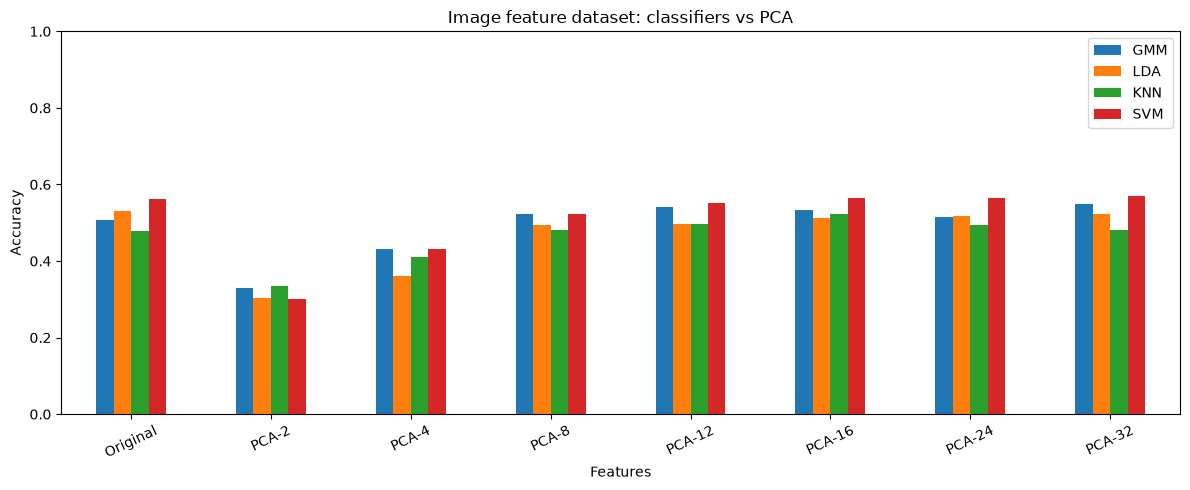

In [7]:
results=[]
for k in [None,2,4,8,12,16,24,32]:
    if k is not None and k>=A.shape[1]: continue
    scores=evaluate_classifiers(X_fit,y_fit,X_test,y_test,pca_k=k)
    results.append({"Features":"Original" if k is None else f"PCA-{k}",**scores})
    print(results[-1])
result_df=pd.DataFrame(results); display(result_df)
ax=result_df.set_index("Features")[["GMM","LDA","KNN","SVM"]].plot(kind="bar",ylim=(0,1),figsize=(12,5))
ax.set_ylabel("Accuracy"); ax.set_title("Image feature dataset: classifiers vs PCA"); plt.xticks(rotation=25); plt.tight_layout(); plt.show()
result_df.to_csv(OUT/"image_results.csv",index=False)